In [54]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import utils as ut

from sklearn.datasets import fetch_openml

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# L2 regularisation

To combat overfitting, L2 regularisation adds a penalty for large weights:
$$C_{\text{total}} = C_{\text{cross-entropy}}+\frac\lambda2\sum_{k,c} w_{kc}^2$$

The hyperparameter $\lambda$ controls how strongly large weights are discouraged. Small $\lambda$ gives more freedom to fit the training data, leading to potential overfitting, whereas large $\lambda$ enforces stronger constraints on the weights and can lead to underfitting.

Gradient descent of weights requires

$$w^{\text{new}}_{kc}=w_{kc} -\nu\frac{\partial C_{\text{total}}}{\partial w_{kc}}$$

Differentiating $C_{\text{total}}=C_{\text{CE}}+\frac\lambda2\sum_{k,c}w_{kc}^2$ with respect to $w_{kc}$, we get

$$\frac{\partial C_{\text{total}}}{\partial w_{kc}}=\frac{\partial C_{\text{CE}}}{\partial w_{kc}}+\frac{\partial}{\partial w_{kc}}\left(\frac\lambda2\sum_{j,d}w_{jd}^2\right)$$

Simplifying the second term,

$$\frac{\partial}{\partial w_{kc}}\left(\frac\lambda2\sum_{j,d}w_{jd}^2\right)=\frac\lambda2(2w_{kc})=\lambda w_{kc}$$

Hence we obtain our new formula for gradient descent of weights

$$\boxed{\frac{\partial C_{\text{total}}}{\partial w_{kc}}=\frac{\partial C_{\text{CE}}}{\partial w_{kc}}+\lambda w_{kc}}$$

Implementing this requires a small modification to the training function `train()`, which is located in `utils.py`. The function is otherwise identical to the implementation in `introduction.ipynb`.

In [55]:
# retrieve MNIST dataset via OpenML
X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
y = y.astype(int)

# normalise to values between 0 and 1
X = X.astype(np.float64) / 255.0

# name images as X and labels as y for conciseness
# first 60,000 pairs are used for training.
X_train = X[:60000]
y_train = y[:60000]

# remaining 10,000 are used for testing
X_test = X[60000:]
y_test = y[60000:]

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(60000, 784) (60000,)
(10000, 784) (10000,)


# Determining best $\lambda$ using K-fold cross-validation
First, we divide the training dataset of 60,000 samples into five portions (aka folds). We choose one particular value of $\lambda$, train on four folds and test the accuracy on the remaining fold. We repeat five times, choosing a different fold for testing each time. We then obtain five accuracies. Averaging this, we obtain a final validation accuracy for this $\lambda$. We repeat across all values of $\lambda$ and compare validation accuracies to find the best one.

In [56]:
lams = [0, 0.0001, 0.001, 0.01, 0.1, 1]

N = 60000
K = 5

rng = np.random.default_rng(42)
indices = rng.permutation(N) # randomly arranges the images in the training sample with the RNG seed 42

folds = np.array_split(indices, K) # separates the training dataset into K folds

In [57]:
# for one loop as a proof-of-concept

lam = 0.01
accuracies = []

for k in range(K):
    val_indices = folds[k]

    train_indices = np.concatenate([folds[j] for j in range(K) if j != k])

    X_tr = X_train[train_indices]
    y_tr = y_train[train_indices]

    X_val = X_train[val_indices]
    y_val = y_train[val_indices]

    W, b = ut.train(X_tr, y_tr, learning_rate=0.7, epochs=100, lam=lam)

    predictions = ut.predict(X_val, W, b)
    accuracy = np.mean(predictions == y_val)

    accuracies.append(accuracy)

    print(f"Fold {k+1}: {accuracy:.4f}")

print("Mean validation accuracy:", np.mean(accuracies))

Fold 1: 0.8930
Fold 2: 0.8951
Fold 3: 0.8943
Fold 4: 0.8895
Fold 5: 0.8955
Mean validation accuracy: 0.8934833333333334


In [58]:
mean_accuracies = []

for lam in lams:
    accuracies = []

    for k in range(K):
        val_indices = folds[k]
        train_indices = np.concatenate([folds[j] for j in range(K) if j != k])

        X_tr = X_train[train_indices]
        y_tr = y_train[train_indices]

        X_val = X_train[val_indices]
        y_val = y_train[val_indices]

        W, b = ut.train(X_tr, y_tr, learning_rate=0.3, epochs=2000, lam=lam)

        predictions = ut.predict(X_val, W, b)
        accuracy = np.mean(predictions == y_val)

        accuracies.append(accuracy)

    mean_accuracy = np.mean(accuracies)
    mean_accuracies.append(mean_accuracy)

    print(f"lambda = {lam}: mean accuracy = {mean_accuracy:.4f}")

lambda = 0: mean accuracy = 0.9173
lambda = 0.0001: mean accuracy = 0.9170
lambda = 0.001: mean accuracy = 0.9149
lambda = 0.01: mean accuracy = 0.8998
lambda = 0.1: mean accuracy = 0.8623
lambda = 1: mean accuracy = 0.7681


# Results

**learning_rate = 0.3, epochs = 500**
```text
lambda = 0:      mean accuracy = 0.9063
lambda = 0.0001: mean accuracy = 0.9062
lambda = 0.001:  mean accuracy = 0.9056
lambda = 0.01:   mean accuracy = 0.8986
lambda = 0.1:    mean accuracy = 0.8640
lambda = 1:      mean accuracy = 0.7688
```

**learning_rate = 0.3, epochs = 1000**
```text
lambda = 0:      mean accuracy = 0.9136
lambda = 0.0001: mean accuracy = 0.9134
lambda = 0.001:  mean accuracy = 0.9118
lambda = 0.01:   mean accuracy = 0.9001
lambda = 0.1:    mean accuracy = 0.8629
lambda = 1:      mean accuracy = 0.7680
```

**learning_rate = 0.3, epochs = 2000**
```text
lambda = 0:      mean accuracy = 0.9173
lambda = 0.0001: mean accuracy = 0.9170
lambda = 0.001:  mean accuracy = 0.9149
lambda = 0.01:   mean accuracy = 0.8998
lambda = 0.1:    mean accuracy = 0.8623
lambda = 1:      mean accuracy = 0.7681
```

# Testing on test dataset
Here we identify that $\lambda=0$ (ie no regularisation at all) is the best choice. We train one final model accordingly on the whole training dataset and validate it using the testing dataset.

In [59]:
W, b = ut.train(X_train, y_train, learning_rate=0.3, epochs=2000, lam=0)

predictions = ut.predict(X_test, W, b)
accuracy = np.mean(predictions == y_test)
print(f"Test accuracy: {accuracy:.4f}")

Test accuracy: 0.9222


# Interactive segment

Here is a little interactive code where one can input an index between 0 and 9999. The image is depicted along with the model's predicted value.

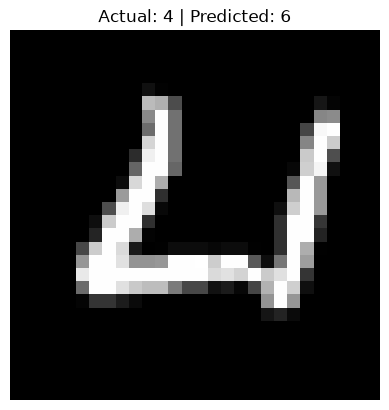

Predicted digit: 6
Probability: 48.00%


In [104]:
# Choose an image from the test dataset (0–9999)
i = 33

image = X_test[i]
actual = y_test[i]

# Predict the digit
prediction = ut.predict(image.reshape(1, 784), W, b)[0]

# Display the image
plt.imshow(image.reshape(28, 28), cmap="gray")
plt.title(f"Actual: {actual} | Predicted: {prediction}")
plt.axis("off")
plt.show()

# Calculate probabilities for all 10 digits
Z = image @ W + b
P = ut.softmax(Z.reshape(1, 10))[0]

# Print the prediction and its probability
print(f"Predicted digit: {prediction}")
print(f"Probability: {P[prediction]:.2%}")